# 03: a pretrained ResNet on the artworks (milestone m3)

In m1 our dense network got 0.380 on the test set. In m2 we saw why it stays low: it flattens the image, so it does
not know which pixels are next to each other, and it has 6.3 million weights for only 1 000 training images.

Here we do what Session 7 suggests. We take a ResNet-18 that was already trained on ImageNet (1.2 million photos) and
we adapt it to our 5 genres. We follow Part D of TP07, where the prof does the same thing on CIFAR-10.

## Imports

Same as in notebooks 01 and 02, plus:

- `torchvision.models`: the ResNet-18 and its pretrained weights;
- `time`: to see how long the training takes.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import confusion_matrix

DATA_DIR = "data/wikiart_genre5"
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(4)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Helper functions

`evaluate` is the same function as in TP07 (and in our notebooks 01 and 02): it gives the loss and the accuracy of a
model on a loader. `count_parameters` counts the weights of a model; with `trainable_only=True` it only counts the
ones that the training is allowed to change.

In [2]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

## The data

We load the images and split them exactly like in notebooks 01 and 02 (same split by artist, same seed): the same
1 000 training images, the same 250 validation images, and above all the same 250 test images, so that the
comparison with the dense network is fair.

In [3]:
folder = datasets.ImageFolder(DATA_DIR)
CLASSES = folder.classes
images = np.stack([np.array(img) for img, _ in folder])          # (N, 128, 128, 3), uint8, values 0 to 255
X_full = torch.tensor(images).permute(0, 3, 1, 2).float() / 255  # (N, 3, 128, 128), pixels in [0, 1]
y_full = torch.tensor(folder.targets)                             # (N,), int64

print("X_full", tuple(X_full.shape), X_full.dtype, "| y_full", tuple(y_full.shape), y_full.dtype)
print("images per class:", dict(zip(CLASSES, torch.bincount(y_full).tolist())))

X_full (1500, 3, 128, 128) torch.float32 | y_full (1500,) torch.int64
images per class: {'cityscape': 300, 'landscape': 300, 'portrait': 300, 'religious_painting': 300, 'still_life': 300}


In [4]:
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv")).set_index("path")
artist = [meta.loc[os.path.relpath(p, DATA_DIR), "artist"] for p, _ in folder.samples]
# one group per named artist; "Unknown Artist" is a catch-all of many painters, so each of its images is its own group
group = [a if a != "Unknown Artist" else f"unknown_{i}" for i, a in enumerate(artist)]
names = sorted(set(group))
members = {g: [i for i, h in enumerate(group) if h == g] for g in names}

# groups in a random order: a group goes to test if it fits there (at most 1/6 of each class), else to validation,
# else to train. Classes stay balanced and an artist never appears in two sets.
order = torch.randperm(len(names), generator=torch.Generator().manual_seed(0)).tolist()
per_class = torch.bincount(y_full) // 6                         # 50 images of each class in test and in validation
filled = {"test": torch.zeros(len(CLASSES), dtype=torch.int64), "val": torch.zeros(len(CLASSES), dtype=torch.int64)}
split = {"train": [], "val": [], "test": []}
for k in order:
    idx = members[names[k]]
    counts = torch.bincount(y_full[idx], minlength=len(CLASSES))
    s = next((s for s in ["test", "val"] if (filled[s] + counts <= per_class).all()), "train")
    if s != "train":
        filled[s] += counts
    split[s] += idx
train_idx, val_idx, test_idx = (torch.tensor(sorted(split[s])) for s in ["train", "val", "test"])

X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
X_test_raw, y_test = X_full[test_idx], y_full[test_idx]

named = {s: {artist[i] for i in split[s]} - {"Unknown Artist"} for s in split}
assert not (named["train"] & named["val"] or named["train"] & named["test"] or named["val"] & named["test"]), "an artist is on both sides"
print(f"train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)} | no named artist in two sets")
for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{s:5s}", dict(zip(CLASSES, torch.bincount(y, minlength=len(CLASSES)).tolist())))

train 1000, val 250, test 250 | no named artist in two sets
train {'cityscape': 200, 'landscape': 200, 'portrait': 200, 'religious_painting': 200, 'still_life': 200}
val   {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}
test  {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}


**Preparing the images for the ResNet.** A pretrained model must get its inputs prepared the same way as during its
pre-training (TP07). The ResNet was trained on ImageNet photos where each colour channel was normalised with the
ImageNet mean and standard deviation. So we do the same here, channel by channel, instead of using the mean and std of
our own training images like in m1. Our images are 128 x 128: smaller than the 224 x 224 of ImageNet, but the ResNet
works with any size, and it keeps the training fast enough on a CPU.

`fit_transfer` is the training function of TP07. One detail: the model stays in `eval()` mode during the training.
The ResNet has batch norm layers that keep running averages learned on ImageNet. With only 1 000 images we do not
want to change them. The weights themselves are still trained normally. After each epoch we measure the accuracy on
the training set and on the validation set, like in m2, to see if the model overfits.

In [5]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prepare(X):
    return (X - IMAGENET_MEAN) / IMAGENET_STD


train_loader = DataLoader(TensorDataset(prepare(X_train_raw), y_train), batch_size=64, shuffle=True)
train_eval_loader = DataLoader(TensorDataset(prepare(X_train_raw), y_train), batch_size=250)
val_loader = DataLoader(TensorDataset(prepare(X_val_raw), y_val), batch_size=250)
test_loader = DataLoader(TensorDataset(prepare(X_test_raw), y_test), batch_size=250)
loss_fn = nn.CrossEntropyLoss()


def fit_transfer(model, optimizer, n_epochs):
    torch.manual_seed(1)
    history = {"train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        t0 = time.time()
        model.eval()                                   # batch norm keeps its ImageNet statistics
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
        _, train_acc = evaluate(model, train_eval_loader, loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"epoch {epoch + 1}: train acc {train_acc:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f} "
              f"({time.time() - t0:.0f} s)")
    return history


print("train", tuple(X_train_raw.shape), "| validation", tuple(X_val_raw.shape), "| test", tuple(X_test_raw.shape))

train (1000, 3, 128, 128) | validation (250, 3, 128, 128) | test (250, 3, 128, 128)


## Load the pretrained ResNet-18

`resnet18(weights=ResNet18_Weights.DEFAULT)` builds a ResNet-18 and loads the weights it learned on ImageNet
(downloaded once, 45 MB). Its last layer, `fc`, gives 1 000 scores, one per ImageNet class. We replace it with a new
`nn.Linear(512, 5)`: 5 scores, one per genre. This new last layer is called the **head**. Like any new layer, it
starts with random weights.

In [6]:
torch.manual_seed(0)
model = resnet18(weights=ResNet18_Weights.DEFAULT)
print("original head:", model.fc)
model.fc = nn.Linear(512, len(CLASSES))
model = model.to(device)
print("new head:", model.fc)
print("parameters:", count_parameters(model))

original head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=5, bias=True)
parameters: 11179077


## Train only the new head

First we **freeze** the rest of the network: with `p.requires_grad = False`, autograd computes no gradient for these
weights, so the optimiser never changes them. Only the head is trained: 512 x 5 + 5 = 2 565 weights, against 6.3
million in our dense network.

The idea: the ResNet already knows how to describe an image. For each painting it gives 512 numbers (edges, colours,
textures, shapes it learned on ImageNet), and the head only has to learn how to read these 512 numbers to find the
genre.

We use Adam with a learning rate of 3e-3 for 3 epochs, like in TP07. Adam is a version of gradient descent that adapts
the step of each weight (Session 6); a new layer can learn fast, hence the rather large learning rate.

In [7]:
for p in model.parameters():
    p.requires_grad = False          # freeze the whole network
for p in model.fc.parameters():
    p.requires_grad = True           # except the new head
print("trainable:", count_parameters(model, trainable_only=True), "of", count_parameters(model))

EPOCHS_HEAD = 3
optimizer = torch.optim.Adam(model.fc.parameters(), lr=3e-3)
history_head = fit_transfer(model, optimizer, EPOCHS_HEAD)

trainable: 2565 of 11179077


epoch 1: train acc 0.775 | val loss 0.752 | val acc 0.724 (17 s)


epoch 2: train acc 0.806 | val loss 0.755 | val acc 0.716 (18 s)


epoch 3: train acc 0.852 | val loss 0.728 | val acc 0.748 (16 s)


## Fine-tune the last block

`layer4` is the last block of the ResNet. It computes the most specific features, the ones most tied to the ImageNet
photos. Paintings are not photos, so we let this block adapt a little: we unfreeze it and train it together with the
head. This is the **fine-tuning**.

The pretrained weights only need small changes, and we do not want to destroy what they learned. So `layer4` gets a
smaller learning rate (1e-4) than the head (1e-3). An optimiser accepts groups of parameters, each with its own
learning rate. 3 epochs, like in TP07.

In [8]:
for p in model.layer4.parameters():
    p.requires_grad = True           # unfreeze the last block
print("trainable:", count_parameters(model, trainable_only=True), "of", count_parameters(model))

EPOCHS_FT = 3
optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-4},
                              {"params": model.fc.parameters(), "lr": 1e-3}])
history_ft = fit_transfer(model, optimizer, EPOCHS_FT)

trainable: 8396293 of 11179077


epoch 1: train acc 0.848 | val loss 0.869 | val acc 0.688 (18 s)


epoch 2: train acc 0.949 | val loss 0.911 | val acc 0.752 (17 s)


epoch 3: train acc 0.998 | val loss 0.863 | val acc 0.764 (17 s)


## Choose the model, then measure it once on the test set

We choose on the validation set, never on the test set. After fine-tuning, the validation accuracy is 0.764, against
0.748 with the head alone. That is only 4 images more out of 250, so the gain is small, but it is the model asked for
in this milestone, so we keep the fine-tuned one.

Then we measure it **once** on the test set: the same 250 paintings as in m1, by 17 artists that are not in the
training set.

In [9]:
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
print(f"test accuracy of the fine-tuned ResNet-18: {test_acc:.3f} (dense baseline of m1: 0.380, chance level: 0.20)")

test accuracy of the fine-tuned ResNet-18: 0.772 (dense baseline of m1: 0.380, chance level: 0.20)


## The confusion matrix

Same reading as in m1: one row per true genre (50 test paintings each), one column per predicted genre, the correct
answers on the diagonal.

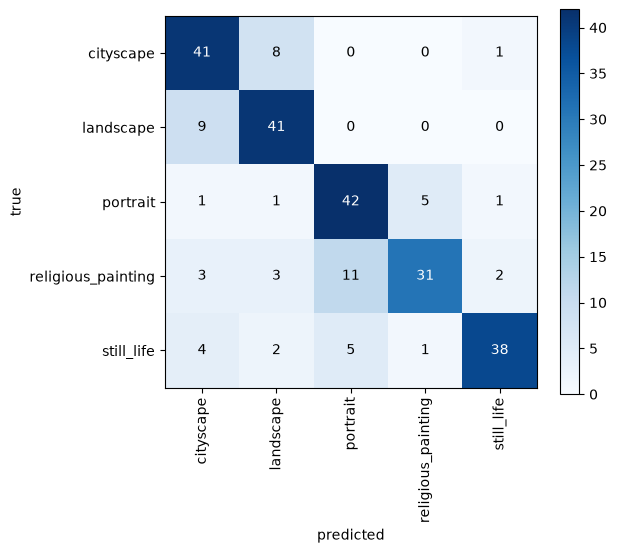

correct per genre: {'cityscape': 41, 'landscape': 41, 'portrait': 42, 'religious_painting': 31, 'still_life': 38}
most frequent mistake: religious_painting predicted as portrait (11 times)


In [10]:
model.eval()
with torch.no_grad():
    pred = model(prepare(X_test_raw).to(device)).argmax(dim=1).cpu()   # predicted genre of every test painting

cm = confusion_matrix(y_test.numpy(), pred.numpy())
off = cm.copy()
np.fill_diagonal(off, 0)                                   # ignore the correct predictions
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(len(CLASSES)), CLASSES, rotation=90); plt.yticks(range(len(CLASSES)), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
print("correct per genre:", dict(zip(CLASSES, np.diag(cm).tolist())))
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")

## Dense network versus ResNet

The two models side by side, on the same test set. The numbers of the dense network come from notebook 01.

In [11]:
comparison = pd.DataFrame.from_dict({
    "dense baseline (m1)": [0.380, 6_292_229, 6_292_229],
    "ResNet-18 fine-tuned (m3)": [round(test_acc, 3), count_parameters(model), count_parameters(model, trainable_only=True)],
}, orient="index", columns=["test accuracy", "parameters", "trained parameters"])
print(comparison)

                           test accuracy  parameters  trained parameters
dense baseline (m1)                0.380     6292229             6292229
ResNet-18 fine-tuned (m3)          0.772    11179077             8396293


**What we see.** The pretrained ResNet gets 0.772 on the test set: 193 paintings right out of 250, against 95 for the
dense network (0.380). That is twice better, and almost 4 times the chance level.

- Religious paintings: 31 right out of 50, against 4 with the dense network. When the ResNet is wrong on them, it
  mostly says portrait (11 times). Many religious paintings show people, so this mistake makes sense.
- Landscapes and cityscapes are still mixed up a bit (9 and 8 times), but much less than in m1 (21 and 15).
- Why such a jump? The ResNet does not flatten the image: its convolutions look at small patches and keep track of
  which pixels are next to each other (Session 7). And it already learned to see edges, textures and shapes on 1.2
  million photos. We only had to teach it our 5 genres.
- The lesson of m2 still holds: after fine-tuning, the training accuracy is 0.998 and the validation loss went up
  (0.728 with the head alone, 0.863 after fine-tuning), for only 4 more images right on the validation set. With
  1 000 images, a few epochs are enough, more would only overfit.
- The cost: the ResNet has 11.2 million parameters, almost twice the dense network, and the whole training took about
  2 minutes on a laptop CPU. For the director's question (kiosks with modest CPUs), the size and the prediction time
  of each model will have to be measured.